In [1]:
import sys
sys.path.append('..')
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from src.data_prep import filter_residential, trim_price_outliers

sns.set_palette('colorblind')
df = pd.read_csv('../data/processed/london_house_prices.csv', parse_dates=['date_of_transfer'])
df.shape

(302729, 18)

## missingness

saon/locality nulls are expected (not every address has a sub-unit or locality). price/date/postcode/coords are the fields that matter and have zero nulls.

In [2]:
df.isnull().mean().sort_values(ascending=False)

locality             0.936468
saon                 0.623066
street               0.000020
lat                  0.000000
record_status        0.000000
ppd_category_type    0.000000
county               0.000000
district             0.000000
town_city            0.000000
transaction_id       0.000000
price                0.000000
paon                 0.000000
duration             0.000000
old_new              0.000000
property_type        0.000000
postcode             0.000000
date_of_transfer     0.000000
long                 0.000000
dtype: float64

## category type / property type

category b (repossessions, buy-to-lets, transfers under power of sale) and property_type o (commercial/other) carry extreme non-residential prices, up to £793m. plan scope is residential avm, so these get filtered out via `filter_residential`.

In [3]:
df.groupby('ppd_category_type')['price'].describe()

,count,mean,std,min,25%,50%,75%,max
ppd_category_type,,,,,,,,
A,241179.0,7.192215e+05,1.431864e+06,1.0,395000.0,530000.0,763220.0,540000000.0
B,61550.0,1.132541e+06,6.077833e+06,100.0,290000.0,427260.5,662000.0,793020000.0


In [4]:
df = filter_residential(df)
df.shape, df['price'].describe()

((241179, 18),
 count    2.411790e+05
 mean     7.192215e+05
 std      1.431864e+06
 min      1.000000e+00
 25%      3.950000e+05
 50%      5.300000e+05
 75%      7.632200e+05
 max      5.400000e+08
 Name: price, dtype: float64)

## price outliers within category a

category a still has £1 transfers (non-arm's-length, e.g. family gifts) and at least one clear data error (a £540m terraced house in E4). floor + top-0.1% trim via `trim_price_outliers`; the remaining upper tail (£10-75m, mostly SW1X/W2/W11 flats) is plausible prime-london stock, kept as is.

In [5]:
df = trim_price_outliers(df)
df.shape, df['price'].describe()

((240932, 18),
 count    2.409320e+05
 mean     6.990964e+05
 std      6.636754e+05
 min      4.650000e+04
 25%      3.950000e+05
 50%      5.300000e+05
 75%      7.600252e+05
 max      1.110000e+07
 Name: price, dtype: float64)

## price distribution

raw price is heavily right-skewed (typical for house prices) -- log scale is closer to normal and is what the models will target.

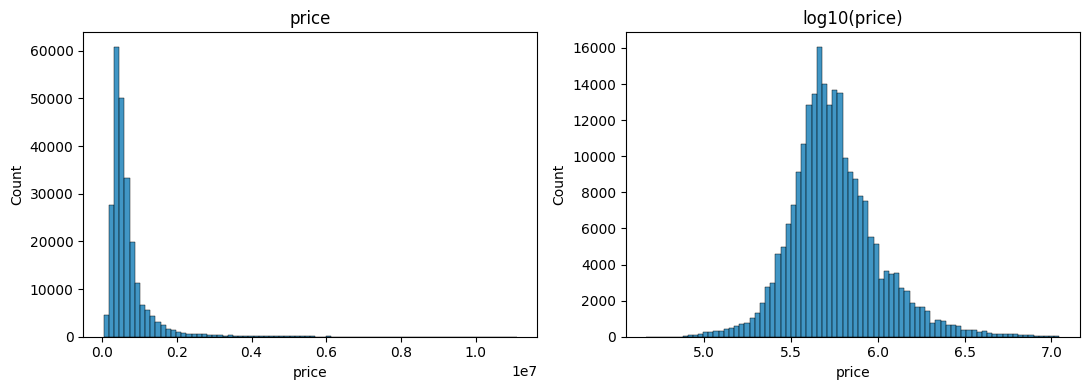

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df['price'], bins=80, ax=axes[0])
axes[0].set_title('price')
sns.histplot(df['price'].apply('log10'), bins=80, ax=axes[1])
axes[1].set_title('log10(price)')
plt.tight_layout()

## price trend over time

monthly median, by property type.

Text(0.5, 1.0, 'greater london monthly median price by property type')

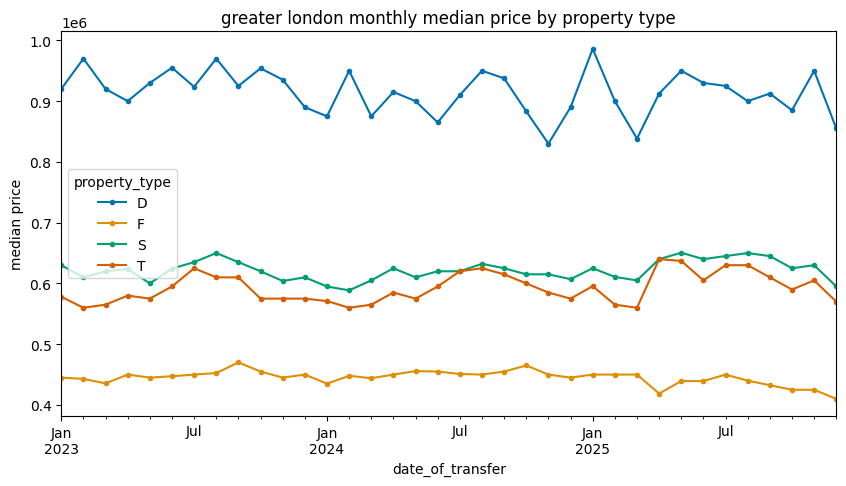

In [7]:
monthly = df.groupby([df['date_of_transfer'].dt.to_period('M'), 'property_type'])['price'].median().unstack()
monthly.index = monthly.index.to_timestamp()
monthly.plot(figsize=(10, 5), marker='o', markersize=3)
plt.ylabel('median price')
plt.title('greater london monthly median price by property type')

## geographic scatter

sampled points (full set is too dense to render), colored by log price.

In [8]:
sample = df.sample(8000, random_state=0).copy()
sample['log_price'] = sample['price'].apply('log10')
fig = px.scatter_map(
    sample, lat='lat', lon='long', color='log_price',
    color_continuous_scale='viridis', map_style='carto-positron',
    zoom=8.5, height=650, opacity=0.6,
)
fig.show()

## transaction volume over time

completions per month -- not just price, whether the market is actually active.

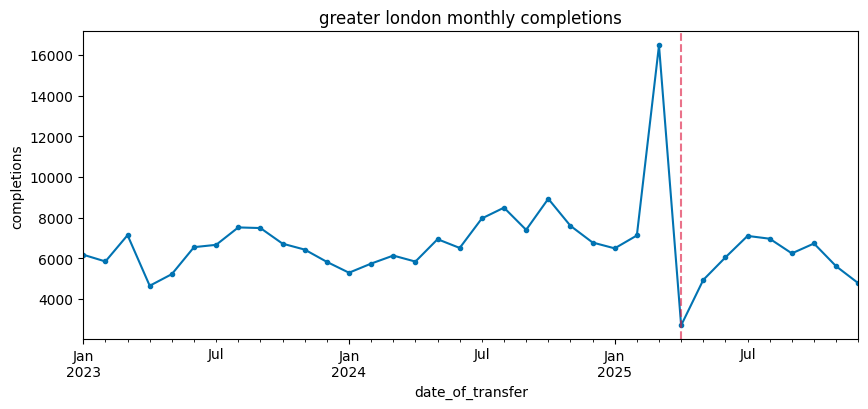

In [9]:
monthly_counts = df.groupby(df['date_of_transfer'].dt.to_period('M')).size()
monthly_counts.index = monthly_counts.index.to_timestamp()
monthly_counts.plot(figsize=(10, 4), marker='o', markersize=3)
plt.ylabel('completions')
plt.title('greater london monthly completions')
plt.axvline(pd.Timestamp('2025-04-01'), color='crimson', linestyle='--', alpha=0.6)

sharp spike in march 2025 (16.5k, vs a 6-8k baseline) then a trough in april (2.7k) -- this lines up exactly with the SDLT (stamp duty) nil-rate band reverting on 1 april 2025, which pulled a wave of completions forward to beat the deadline. real policy effect, not a data quality issue, but it does mean march/april 2025 sit outside the normal seasonal pattern -- `sale_month` alone won't capture it, and if this project extended past a single window it'd be worth a one-off SDLT-rush flag.

## property attributes

property_type, old_new, duration -- the categorical features going into every model.

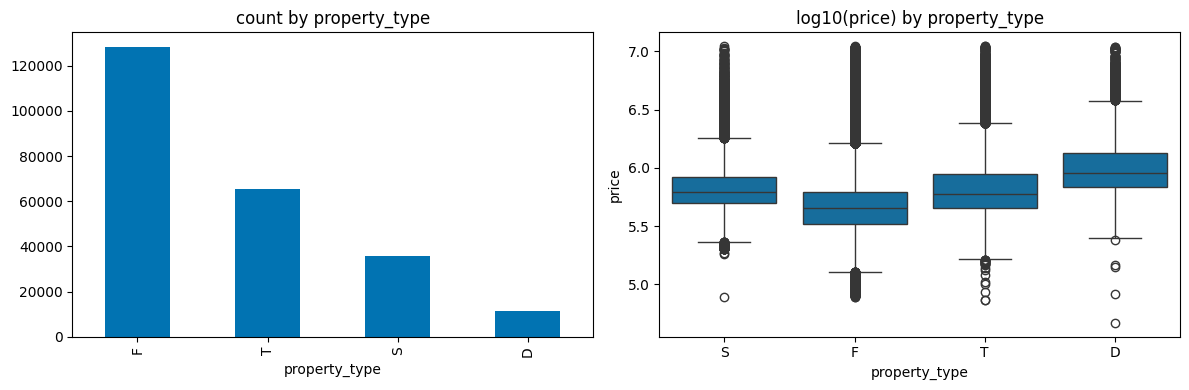

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df['property_type'].value_counts().plot.bar(ax=axes[0])
axes[0].set_title('count by property_type')
sns.boxplot(df, x='property_type', y=df['price'].apply('log10'), ax=axes[1])
axes[1].set_title('log10(price) by property_type')
plt.tight_layout()

flats (F) and terraces (T) dominate volume. detached (D) carries the highest median price and widest spread, semis (S) sit between terrace and detached as expected.

In [11]:
df.groupby('old_new')['price'].describe()[['count', 'mean', '50%']]

,count,mean,50%
old_new,,,
N,225668.0,691003.380501,525000.0
Y,15264.0,818746.780922,597866.0


new builds (Y) are ~2% of sales but carry a real premium over existing stock (old_new N) at the median -- consistent with a new-build markup, worth keeping as a feature even though it's a small class.

In [12]:
pd.crosstab(df['property_type'], df['duration'], normalize='index')

duration,F,L
property_type,,
D,0.990299,0.009701
F,0.006542,0.993458
S,0.977713,0.022287
T,0.959807,0.040193


flats are almost entirely leasehold (duration L), houses (D/S/T) are almost entirely freehold -- `duration` and `property_type` are highly collinear by construction (the ground rent/lease structure, not price, drives this), which the SHAP results in the modeling notebook already reflect (tenure and property_type both rank near the top, likely splitting the same signal).

## seasonality

is there a month-of-year effect independent of the year-over-year trend, or is `monthly median` above just drift?

Text(0.5, 1.0, 'within-year seasonal effect, year mean removed')

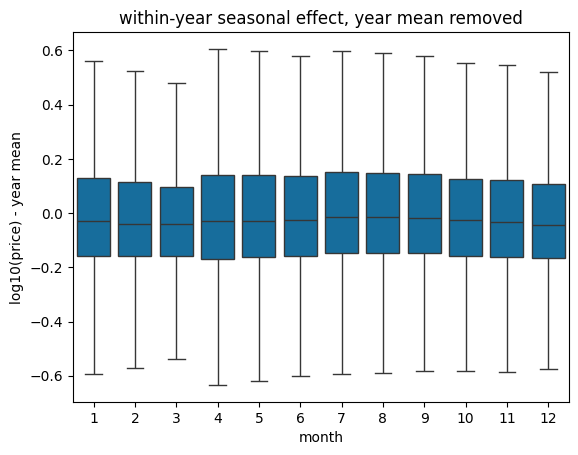

In [13]:
detrended = df.copy()
detrended['year_month_mean'] = detrended.groupby(detrended['date_of_transfer'].dt.to_period('M'))['price'].transform('mean')
detrended['log_price'] = detrended['price'].apply('log10')
detrended['year_mean_log'] = detrended.groupby(detrended['date_of_transfer'].dt.year)['log_price'].transform('mean')
detrended['seasonal_resid'] = detrended['log_price'] - detrended['year_mean_log']

sns.boxplot(detrended, x='sale_month' if 'sale_month' in detrended else detrended['date_of_transfer'].dt.month, y='seasonal_resid', showfliers=False)
plt.ylabel('log10(price) - year mean')
plt.xlabel('month')
plt.title('within-year seasonal effect, year mean removed')

mild but real seasonal pattern -- spring/summer months sit slightly above the year mean, winter (esp. december/january) slightly below. small effect next to the property-attribute and location signal, but it's why `sale_month` is in the feature set rather than just `sale_year`.

## hex resolution choice

`features.py` fixes H3 resolution at 8 -- checking that empirically here rather than taking the comment on faith. resolution 7 hexes are ~5.2km across, 8 are ~0.7km², 9 are ~0.1km² (finer).

,count,min,50%,90%,max
7,375.0,1.0,520.0,1403.8,2816.0
8,2198.0,1.0,85.0,242.0,930.0
9,12220.0,1.0,14.0,42.0,443.0


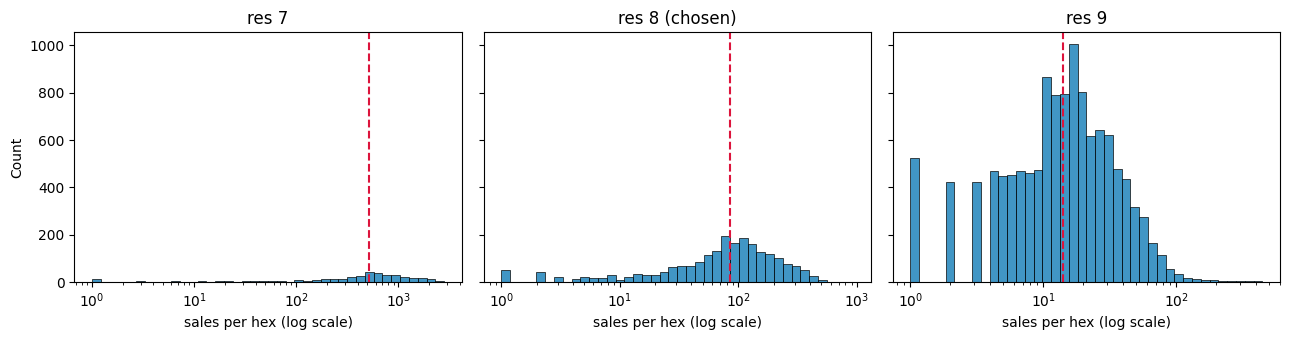

In [14]:
import h3
from src.features import HEX_RESOLUTION

res_counts = {}
for res in [7, 8, 9]:
    hexes = [h3.latlng_to_cell(lat, lon, res) for lat, lon in zip(df['lat'], df['long'])]
    res_counts[res] = pd.Series(hexes).value_counts()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, (res, counts) in zip(axes, res_counts.items()):
    sns.histplot(counts, bins=40, log_scale=(True, False), ax=ax)
    ax.axvline(counts.median(), color='crimson', linestyle='--')
    ax.set_title(f'res {res} (chosen)' if res == HEX_RESOLUTION else f'res {res}')
    ax.set_xlabel('sales per hex (log scale)')
plt.tight_layout()

pd.DataFrame({res: counts.describe(percentiles=[.5, .9]) for res, counts in res_counts.items()}).T[['count', 'min', '50%', '90%', 'max']]

res 7 is too coarse -- hundreds of sales per hex blur genuinely different micro-areas together. res 9 drops most hexes to single digits, too sparse for a stable trailing median. res 8 medians in the tens-to-low-hundreds with the 90th percentile comfortably in double digits -- confirms the choice already made in `features.py`.

## distance to centre vs price

Text(0.5, 1.0, 'price falls off with distance from charing cross (orange = binned median)')

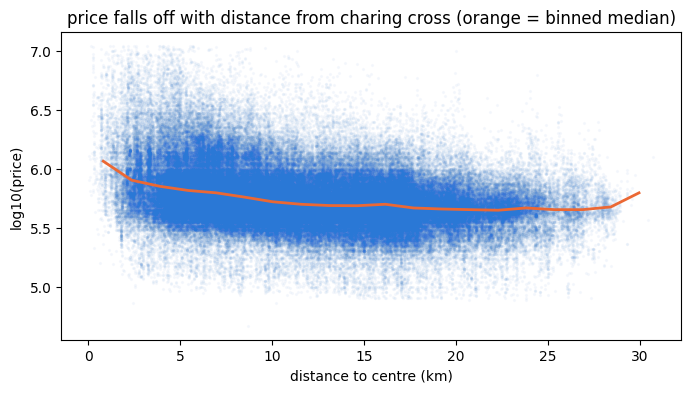

In [15]:
from src.features import add_distance_to_centre

df_dist = add_distance_to_centre(df.copy())
df_dist['log_price'] = df_dist['price'].apply('log10')
df_dist['dist_bin'] = pd.cut(df_dist['dist_to_centre_km'], bins=20)
binned = df_dist.groupby('dist_bin', observed=True)['log_price'].median()

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(df_dist['dist_to_centre_km'], df_dist['log_price'], s=2, alpha=0.03, color='#2a78d6')
ax.plot([b.mid for b in binned.index], binned.values, color='#eb6834', linewidth=2)
ax.set_xlabel('distance to centre (km)')
ax.set_ylabel('log10(price)')
ax.set_title('price falls off with distance from charing cross (orange = binned median)')

clear monotonic decline, roughly log-linear out to ~15km then flattening -- a single distance term captures most of the gradient, but the scatter is wide, meaning distance alone leaves a lot on the table (that's what the hex features are for).

## hex-level price map

median price per res-8 hex, at least 5 sales required so single outlier sales don't dominate a cell.

In [16]:
from src.features import add_hex_id

df_hex = add_hex_id(df_dist.copy())
hex_stats = df_hex.groupby('hex_id').agg(median_price=('price', 'median'), n_sales=('price', 'size'))
hex_stats = hex_stats[hex_stats['n_sales'] >= 5]

def hex_geojson(hex_ids):
    features = []
    for h in hex_ids:
        boundary = h3.cell_to_boundary(h)
        ring = [[lng, lat] for lat, lng in boundary]
        ring.append(ring[0])
        features.append({'type': 'Feature', 'id': h, 'geometry': {'type': 'Polygon', 'coordinates': [ring]}})
    return {'type': 'FeatureCollection', 'features': features}

geojson = hex_geojson(hex_stats.index)
fig = px.choropleth_map(
    hex_stats.reset_index(), geojson=geojson, locations='hex_id',
    color=hex_stats['median_price'].apply('log10').values,
    color_continuous_scale='viridis', map_style='carto-positron',
    center={'lat': 51.5074, 'lon': -0.1278}, zoom=8.5, height=650, opacity=0.75,
    labels={'color': 'log10(median price)'},
)
fig.show()

central/west london hexes dominate as expected, but the map isn't a clean distance gradient -- there are pockets well outside zone 1 (canary wharf, richmond riverside) sitting as high as inner-west-london hexes. that's the motivation for hex-level features over a distance-only model.

## hotspots beyond distance

regress log price on distance alone, then map which hexes sit furthest above that line -- these are the areas distance-to-centre systematically underprices.

In [17]:
from sklearn.linear_model import LinearRegression

X = df_hex[['dist_to_centre_km']]
y = df_hex['price'].apply('log10')
lr = LinearRegression().fit(X, y)
df_hex['dist_resid'] = y - lr.predict(X)

hex_resid = df_hex.groupby('hex_id').agg(mean_resid=('dist_resid', 'mean'), n_sales=('dist_resid', 'size'))
hex_resid = hex_resid[hex_resid['n_sales'] >= 10].sort_values('mean_resid', ascending=False)
hex_resid.head(10)

,mean_resid,n_sales
hex_id,,
88195da457fffff,0.977613,13
88195da41dfffff,0.844247,10
88195daf17fffff,0.764316,11
88194ad737fffff,0.721749,31
88195da757fffff,0.696761,15
88194ad8edfffff,0.614927,17
88195da40bfffff,0.590681,65
88195dae21fffff,0.582053,15
88194ad8e9fffff,0.578358,30


In [18]:
top_hexes = hex_resid.head(10)
centroids = pd.DataFrame([h3.cell_to_latlng(h) for h in top_hexes.index], columns=['lat', 'lon'], index=top_hexes.index)
top_hexes.join(centroids)[['mean_resid', 'n_sales', 'lat', 'lon']]

,mean_resid,n_sales,lat,lon
hex_id,,,,
88195da457fffff,0.977613,13,51.577409,-0.168724
88195da41dfffff,0.844247,10,51.571742,-0.176665
88195daf17fffff,0.764316,11,51.601839,-0.437229
88194ad737fffff,0.721749,31,51.364648,0.046998
88195da757fffff,0.696761,15,51.631661,-0.198664
88194ad8edfffff,0.614927,17,51.418848,-0.269300
88195da40bfffff,0.590681,65,51.579494,-0.180939
88195dae21fffff,0.582053,15,51.609086,-0.396848
88194ad8e9fffff,0.578358,30,51.416776,-0.257108


worth a manual sanity check on the top few centroids against a map -- if they cluster around a named place (canary wharf, richmond, a good school catchment) that's a real, interpretable hotspot the hex features should pick up; if they're scattered, more likely small-n noise despite the `n_sales >= 10` floor.

## feature correlation check

Text(0.5, 1.0, 'feature correlation (hex_trailing_price on log scale)')

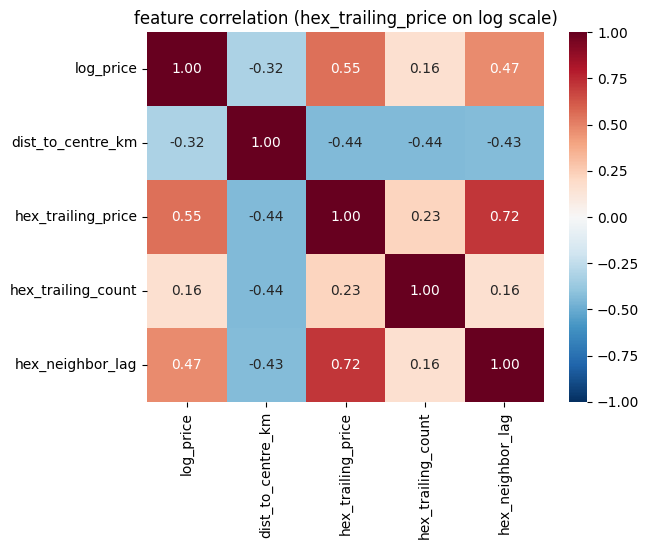

In [19]:
from src.features import add_hex_trailing_stats, add_neighbor_lag, add_date_parts

df_feat = add_date_parts(df_hex.copy())
df_feat, trailing_lookup = add_hex_trailing_stats(df_feat)
df_feat = add_neighbor_lag(df_feat, trailing_lookup)
df_feat['log_price'] = df_feat['price'].apply('log10')

num_cols = ['log_price', 'dist_to_centre_km', 'hex_trailing_price', 'hex_trailing_count', 'hex_neighbor_lag']
corr = df_feat[num_cols].apply(lambda c: c if c.name != 'hex_trailing_price' else c.apply('log10')).corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, center=0)
plt.title('feature correlation (hex_trailing_price on log scale)')

hex_trailing_price correlates strongly with price (expected -- it's a local price aggregate) and with hex_neighbor_lag (expected -- neighbouring hexes are spatially similar). that collinearity between the two hex features is deliberate: neighbor_lag exists specifically to smooth over hexes with thin trailing history, not to add independent signal, so seeing it track hex_trailing_price closely is a sign the leakage-safe construction is doing what it's supposed to rather than a red flag to prune one of them.

## hex price growth, 2023 vs 2025

which areas moved most over the window -- min 10 sales in each year to keep this to hexes with enough signal.

In [20]:
yearly_hex = df_feat[df_feat['sale_year'].isin([2023, 2025])].groupby(['hex_id', 'sale_year'])['price'].agg(['median', 'size']).unstack()
yearly_hex.columns = ['median_2023', 'median_2025', 'n_2023', 'n_2025']
yearly_hex = yearly_hex.dropna()
yearly_hex = yearly_hex[(yearly_hex['n_2023'] >= 10) & (yearly_hex['n_2025'] >= 10)]
yearly_hex['pct_change'] = (yearly_hex['median_2025'] / yearly_hex['median_2023'] - 1) * 100
yearly_hex.sort_values('pct_change', ascending=False).head(10)[['median_2023', 'median_2025', 'pct_change', 'n_2023', 'n_2025']]

,median_2023,median_2025,pct_change,n_2023,n_2025
hex_id,,,,,
88194ad769fffff,365000.0,1050000.0,187.671233,13.0,29.0
88194e680bfffff,247500.0,601840.0,143.167677,16.0,10.0
88194adaadfffff,575000.0,1160000.0,101.739130,23.0,18.0
88194e68ddfffff,266250.0,505000.0,89.671362,20.0,32.0
88195db59bfffff,892450.0,1665000.0,86.565074,20.0,11.0
88195da723fffff,602500.0,1075000.0,78.423237,13.0,15.0
88194ac063fffff,625000.0,1080000.0,72.800000,10.0,11.0
88195da593fffff,623000.0,1070000.0,71.749599,32.0,38.0
88195dac91fffff,437500.0,725000.0,65.714286,12.0,15.0


a handful of hexes show large moves, but with only two annual medians and a 10-sale floor this is noisy -- treat as a starting point for a manual look, not a reliable growth signal on its own. a proper version would need more years or a smoothed trailing trend rather than a two-point comparison.

## handoff to modeling

feature engineering explored here (hex indexing, distance, trailing stats, neighbour lag) lives in `src/features.py` and feeds `02_modeling.ipynb`. summary of what carries forward: property_type/old_new/duration are collinear by tenure structure but each add distinct signal; distance-to-centre captures the broad gradient but leaves real hotspots unexplained; hex_trailing_price and hex_neighbor_lag are correlated by design and both carry into the model; sale_month captures a small but real seasonal effect; the march/april 2025 SDLT rush is a known anomaly in the volume series, not a leak.